# Constructing backtest paths from combinatorial splits

The number of distinct train-test arrangements is given by:

$$
S(N,k)=\binom{N}{k}=\frac{N!}{k!(N-k)!}.
$$

Here, $N$ is the number of time-ordered groups, $k$ is the number of groups placed in each test set, $S(N,k)$ is the number of distinct arrangements, and $!$ denotes the factorial.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display

def compact_float_format(number_format=None):

    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value

def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch('[+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?', rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return '0'
    if ('.' in rendered or 'e' in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered

def compact_numeric_text(text):
    pattern = '(?<![0-9.eE])([+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])'
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)

def compact_table_latex(latex):
    return compact_numeric_text(latex)

def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + '</div>'

def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)
from pathlib import Path
from itertools import combinations
from math import comb
import sys
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
import numpy as np
import pandas as pd
from IPython.display import Image
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
DATA_URL = 'https://data.binance.vision/data/spot/monthly/klines/BTCUSDT/1m/BTCUSDT-1m-2021-01.zip'
DATA_DIR = ROOT / 'data' / 'public' / 'binance'
DATA_PATH = ensure_dataset(ROOT, 'binance_btcusdt')
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
public_columns = ['Open time', 'Open', 'High', 'Low', 'Close', 'Volume', 'Close time', 'Quote volume', 'Trades', 'Buyer base volume', 'Buyer quote volume', 'Unused']
raw = pd.read_csv(DATA_PATH, compression='zip', header=None, names=public_columns, nrows=None)
raw['time'] = pd.to_datetime(raw['Open time'], unit='ms', utc=True).dt.tz_convert(None)
raw = raw.rename(columns={'Close': 'close', 'Volume': 'volume', 'Quote volume': 'quote_volume', 'Trades': 'trades'})
raw = raw.sort_values('time').drop_duplicates('time').reset_index(drop=True)
from RiskLabAI.backtest.validation import AdaptiveCombinatorialPurged, BaggedCombinatorialPurged, CombinatorialPurged, PurgedKFold
FIGURES = ROOT / 'outputs' / 'figures' / '17_combinatorial_purged_cross_validation'
TABLES = ROOT / 'outputs' / 'tables' / '17_combinatorial_purged_cross_validation'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
minute_data = raw.set_index('time')
bars = pd.DataFrame({'Close': minute_data['close'].resample('15min').last(), 'Volume': minute_data['volume'].resample('15min').sum(), 'Quote volume': minute_data['quote_volume'].resample('15min').sum(), 'Trades': minute_data['trades'].resample('15min').sum()}).dropna()
log_close = np.log(bars['Close'])
one_bar_return = log_close.diff()
feature_frame = pd.DataFrame({'Previous return': one_bar_return.shift(1), 'One-hour return': log_close.diff(4).shift(1), 'Past volatility': one_bar_return.shift(1).rolling(16).std(), 'Log volume change': np.log1p(bars['Volume']).diff().shift(1), 'Log quote-volume change': np.log1p(bars['Quote volume']).diff().shift(1), 'Log trade-count change': np.log1p(bars['Trades']).diff().shift(1)})
label_horizon = 8
forward_return = (log_close.shift(-label_horizon) - log_close).rename('Forward return')
direction = forward_return.gt(0).where(forward_return.notna()).astype('Int64').rename('Direction')
end_time = bars.index.to_series().shift(-label_horizon).rename('End time')
public_frame = pd.concat([feature_frame, direction, forward_return, end_time], axis=1).dropna()
public_x = public_frame[feature_frame.columns].astype(float)
public_y = public_frame['Direction'].astype(int)
event_times = public_frame['End time']
external_feature = public_x['Past volatility'].copy()
palette = {'background': '#111827', 'axes': '#111827', 'text': '#E5E7EB', 'cyan': '#38BDF8', 'amber': '#FBBF24', 'green': '#34D399', 'rose': '#FB7185', 'violet': '#C084FC', 'grid': '#374151', 'muted': '#94A3B8'}
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': palette['background'], 'axes.facecolor': palette['axes'], 'axes.edgecolor': palette['text'], 'axes.labelcolor': palette['text'], 'axes.titlecolor': palette['text'], 'xtick.color': palette['text'], 'ytick.color': palette['text'], 'text.color': palette['text'], 'grid.color': palette['grid'], 'grid.linestyle': ':', 'legend.facecolor': palette['axes'], 'legend.edgecolor': palette['grid'], 'savefig.facecolor': palette['background']})

def save_table(frame, stem, caption, label, float_format='%.6f', fit=True):
    frame.to_csv(TABLES / f'{stem}.csv', index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position='H'))
    if fit:
        latex = latex.replace('\\begin{tabular}', '\\begin{adjustbox}{max width=\\textwidth}\\begin{tabular}', 1).replace('\\end{tabular}', '\\end{tabular}\\end{adjustbox}', 1)
    else:
        latex = latex.replace('\\begin{tabular}', '\\centering\n' + '\\begin{tabular}', 1)
    (TABLES / f'{stem}.tex').write_text(latex, encoding='utf-8')

def path_number(name):
    return int(name.rsplit(' ', 1)[1])

def score_path_predictions(method, predictions):
    records = []
    for name in sorted(predictions, key=path_number):
        values = np.asarray(predictions[name]).reshape(-1)
        records.append({'Method': method, 'Path': path_number(name), 'Predictions': len(values), 'Correct predictions': int(np.sum(values == public_y.to_numpy())), 'Accuracy': accuracy_score(public_y, values), 'Positive prediction share': float(np.mean(values == 1))})
    return pd.DataFrame(records)

class ScaledLogisticRegression(ClassifierMixin, BaseEstimator):

    def __init__(self, max_iter=1000, random_state=15):
        self.max_iter = max_iter
        self.random_state = random_state

    def fit(self, data, labels, sample_weight=None):
        self.scaler_ = StandardScaler().fit(data)
        transformed = self.scaler_.transform(data)
        self.model_ = LogisticRegression(max_iter=self.max_iter, solver='lbfgs', random_state=self.random_state)
        self.model_.fit(transformed, labels, sample_weight=sample_weight)
        self.classes_ = self.model_.classes_
        return self

    def predict(self, data):
        return self.model_.predict(self.scaler_.transform(data))

    def predict_proba(self, data):
        return self.model_.predict_proba(self.scaler_.transform(data))

def overlap_count(train_indices, test_indices, times):
    allowed = PurgedKFold.filtered_training_indices_with_embargo(times, times.iloc[test_indices], embargo_fraction=0, continous_test_times=False)
    allowed_positions = set(times.index.get_indexer(allowed.index).tolist())
    return sum((int(int(index) not in allowed_positions) for index in train_indices))
state_colors = ListedColormap([palette['muted'], palette['cyan'], palette['rose'], palette['amber']])
state_norm = BoundaryNorm(np.arange(-0.5, 4.5, 1), state_colors.N)
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': '#111827', 'axes.facecolor': '#111827', 'axes.edgecolor': '#94A3B8', 'axes.labelcolor': '#E5E7EB', 'axes.titlecolor': '#E5E7EB', 'axes.titleweight': 'bold', 'xtick.color': '#94A3B8', 'ytick.color': '#94A3B8', 'text.color': '#E5E7EB', 'grid.color': '#374151', 'grid.linestyle': ':', 'grid.linewidth': 0.8, 'legend.facecolor': '#111827', 'legend.edgecolor': '#374151', 'legend.framealpha': 0.96, 'savefig.facecolor': '#111827', 'savefig.transparent': False, 'savefig.dpi': 300, 'pdf.fonttype': 42, 'ps.fonttype': 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == '3.2.0'


## Public Data

In [2]:
data_provenance = pd.DataFrame({'Field': ['Archive', 'Provider', 'Market', 'Bar length', 'Label horizon', 'Analysis start', 'Analysis end', 'Observations'], 'Value': ['BTCUSDT-1m-2021-01.zip', 'Binance Data Vision', 'Bitcoin to Tether spot market', '15 minutes', '2 hours', str(public_x.index.min()), str(public_x.index.max()), f'{len(public_x):,}']})
save_table(data_provenance, 'data_provenance', 'Fixed public observations used in Chapter 15.', 'tab:chapter15-data-provenance')
display(data_provenance)


,Field,Value
0,Archive,BTCUSDT-1m-2021-1zip
1,Provider,Binance Data Vision
2,Market,Bitcoin to Tether spot market
3,Bar length,15 minutes
4,Label horizon,2 hours
5,Analysis start,2021-01-01 04:15:00
6,Analysis end,2021-01-31 21:45:00
7,Observations,"2,951"


## All Test Combinations

,Groups,Test groups,Training groups,Distinct splits,Test appearances per group,Backtest paths,Nominal training share
0,4,1,3,4,1,1,0.750000
1,4,2,2,6,3,3,0.500000
2,5,1,4,5,1,1,0.800000
3,5,2,3,10,4,4,0.600000
4,6,1,5,6,1,1,0.833333
5,6,2,4,15,5,5,0.666667
6,6,3,3,20,10,10,0.500000
7,7,1,6,7,1,1,0.857143
8,7,2,5,21,6,6,0.714286
9,7,3,4,35,15,15,0.571429


,Group,Test appearances,Path segments
0,1,5,5
1,2,5,5
2,3,5,5
3,4,5,5
4,5,5,5
5,6,5,5


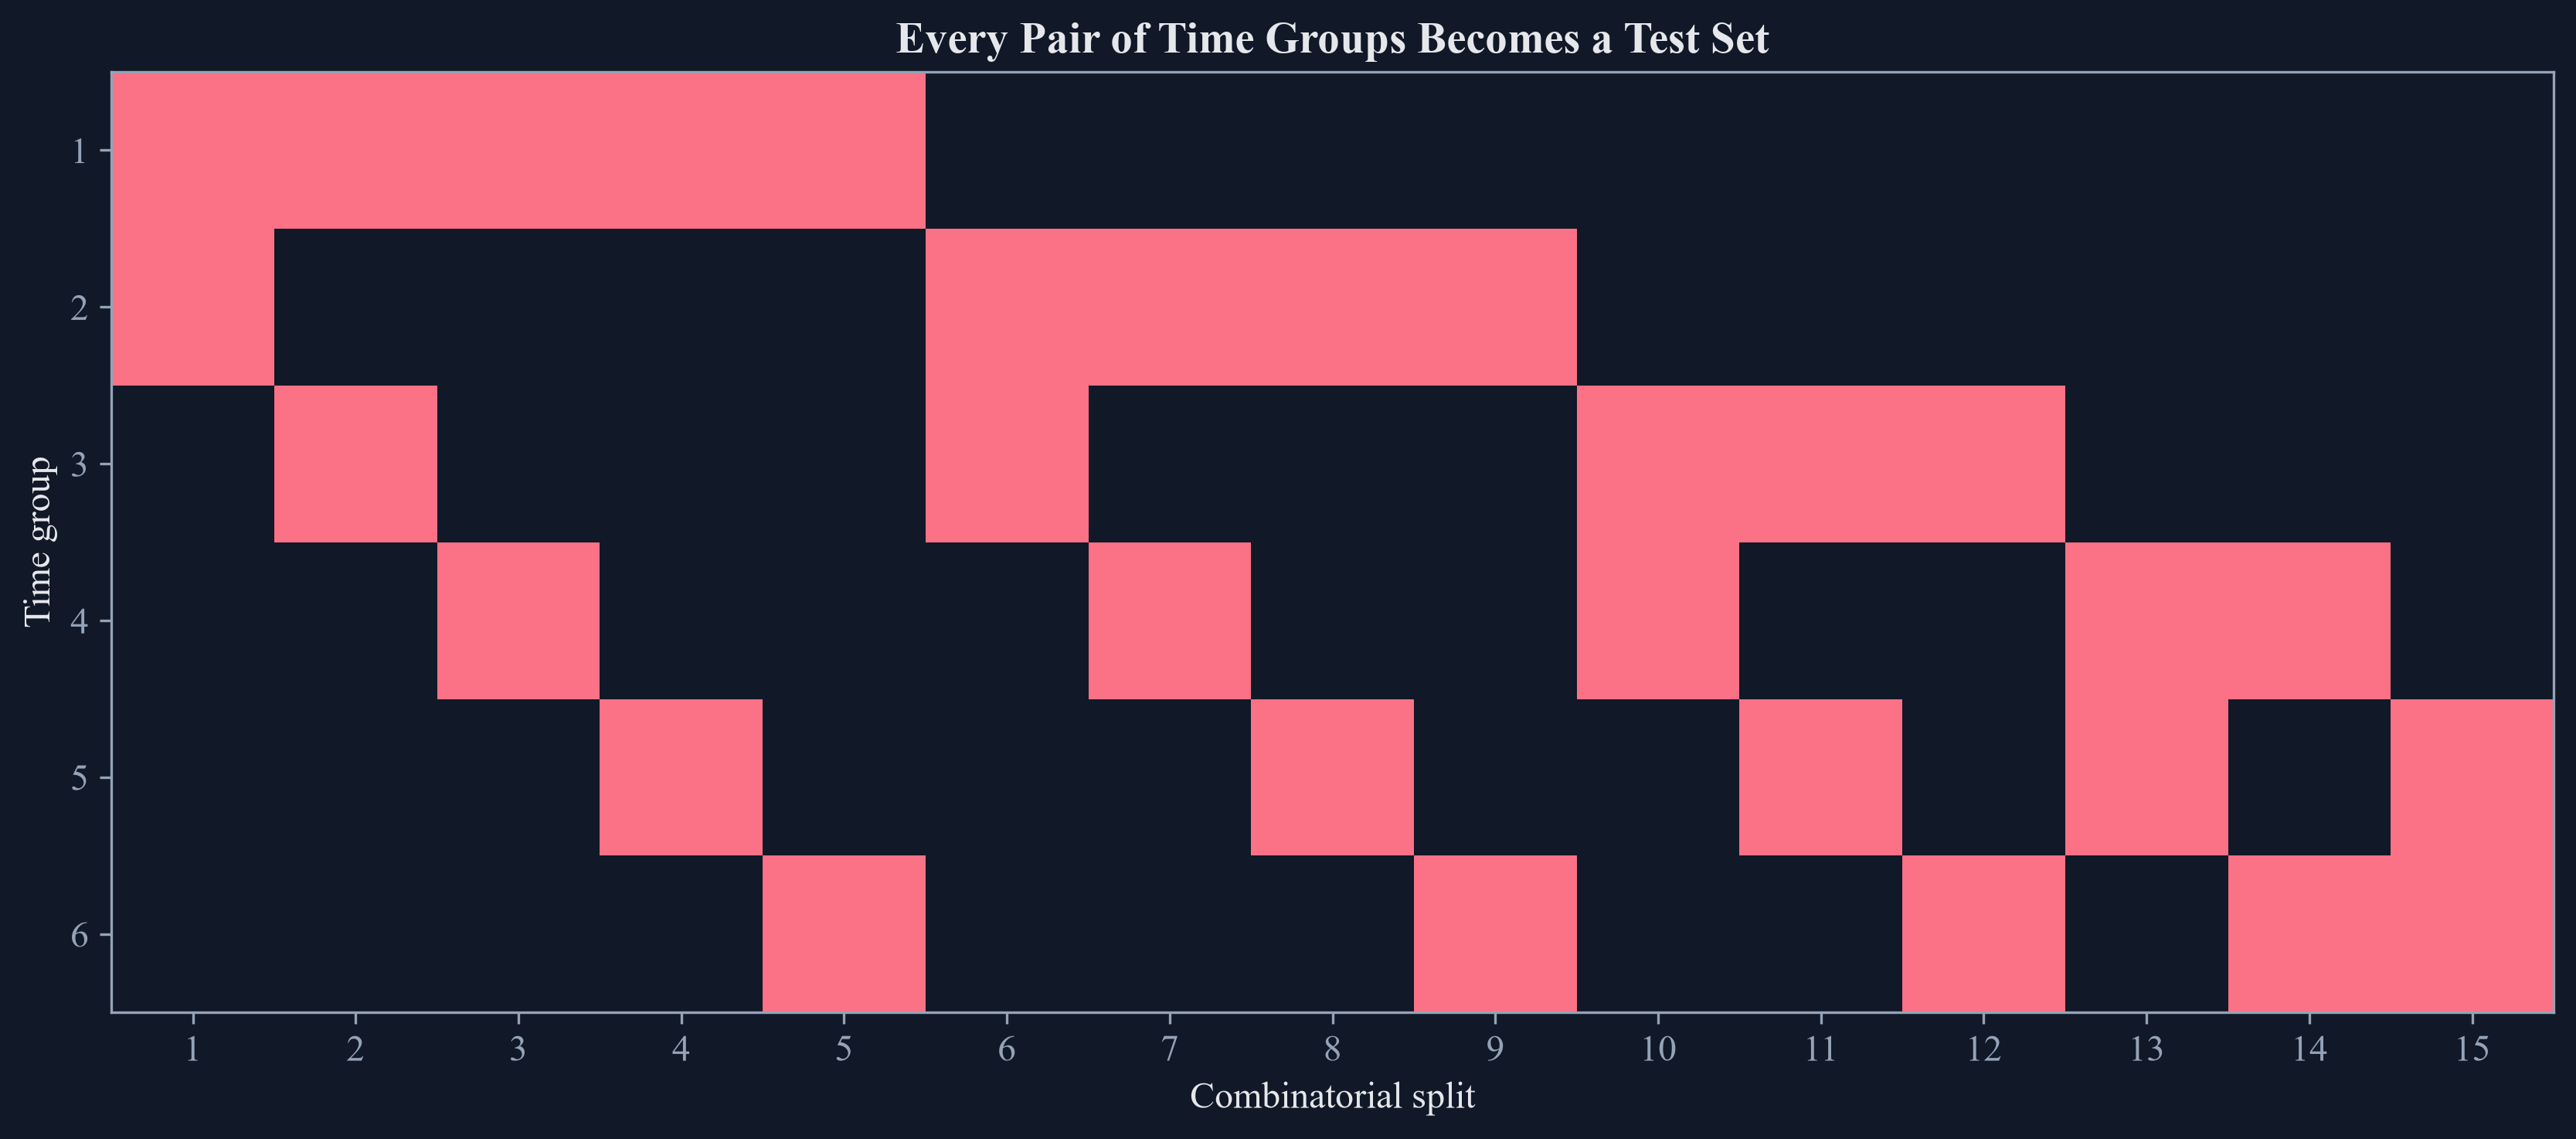

In [3]:
n_groups = 6
n_test_groups = 2
combinations_list = list(combinations(range(n_groups), n_test_groups))
incidence = np.zeros((n_groups, len(combinations_list)), dtype=int)
for split_index, test_groups in enumerate(combinations_list):
    incidence[list(test_groups), split_index] = 1
locations = CombinatorialPurged._path_locations(n_groups, combinations_list)

count_records = []
for groups in range(4, 11):
    for tested in range(1, groups // 2 + 1):
        count_records.append({
            "Groups": groups,
            "Test groups": tested,
            "Training groups": groups - tested,
            "Distinct splits": comb(groups, tested),
            "Test appearances per group": comb(groups - 1, tested - 1),
            "Backtest paths": tested * comb(groups, tested) // groups,
            "Nominal training share": 1 - tested / groups,
        })
combinatorial_counts = pd.DataFrame(count_records)
save_table(combinatorial_counts, "combinatorial_counts", "Split counts, path counts, and nominal training shares for selected combinatorial designs.", "tab:chapter15-combinatorial-counts")
display(combinatorial_counts)

group_test_coverage = pd.DataFrame({
    "Group": np.arange(1, n_groups + 1),
    "Test appearances": incidence.sum(axis=1),
    "Path segments": [sum(group_index == group for path in locations.values() for group_index, _ in path) for group in range(n_groups)],
})
save_table(group_test_coverage, "group_test_coverage", "Uniform test use of each time group for the six-group, two-test-group design.", "tab:chapter15-group-test-coverage", fit=False)
display(group_test_coverage)

figure, axis = plt.subplots(figsize=(11.0, 4.8), constrained_layout=True)
axis.imshow(incidence, aspect="auto", interpolation="nearest", cmap=ListedColormap([palette["axes"], palette["rose"]]), vmin=0, vmax=1)
axis.set_title("Every Pair of Time Groups Becomes a Test Set")
axis.set_xlabel("Combinatorial split")
axis.set_ylabel("Time group")
axis.set_xticks(np.arange(len(combinations_list)))
axis.set_xticklabels(np.arange(1, len(combinations_list) + 1))
axis.set_yticks(np.arange(n_groups))
axis.set_yticklabels(np.arange(1, n_groups + 1))
figure.savefig(FIGURES / "combinatorial_incidence.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "combinatorial_incidence.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "combinatorial_incidence.png")))
plt.close(figure)

Each group appears equally often in testing, and the number of full paths is:

$$
r(N,k)=\binom{N-1}{k-1},
\qquad
\varphi(N,k)=\frac{k}{N}\binom{N}{k}=r(N,k).
$$

Here, $r(N,k)$ is the number of test appearances of each group, $\varphi(N,k)$ is the number of complete backtest paths, and the other symbols retain their earlier meanings. Each complete path uses every group once.

## Assigning Tested Groups to Paths

,Path,Time group,Split,Full test combination
0,1,1,1,1 and 2
1,1,2,1,1 and 2
2,1,3,2,1 and 3
3,1,4,3,1 and 4
4,1,5,4,1 and 5
5,1,6,5,1 and 6
6,2,1,2,1 and 3
7,2,2,6,2 and 3
8,2,3,6,2 and 3
9,2,4,7,2 and 4


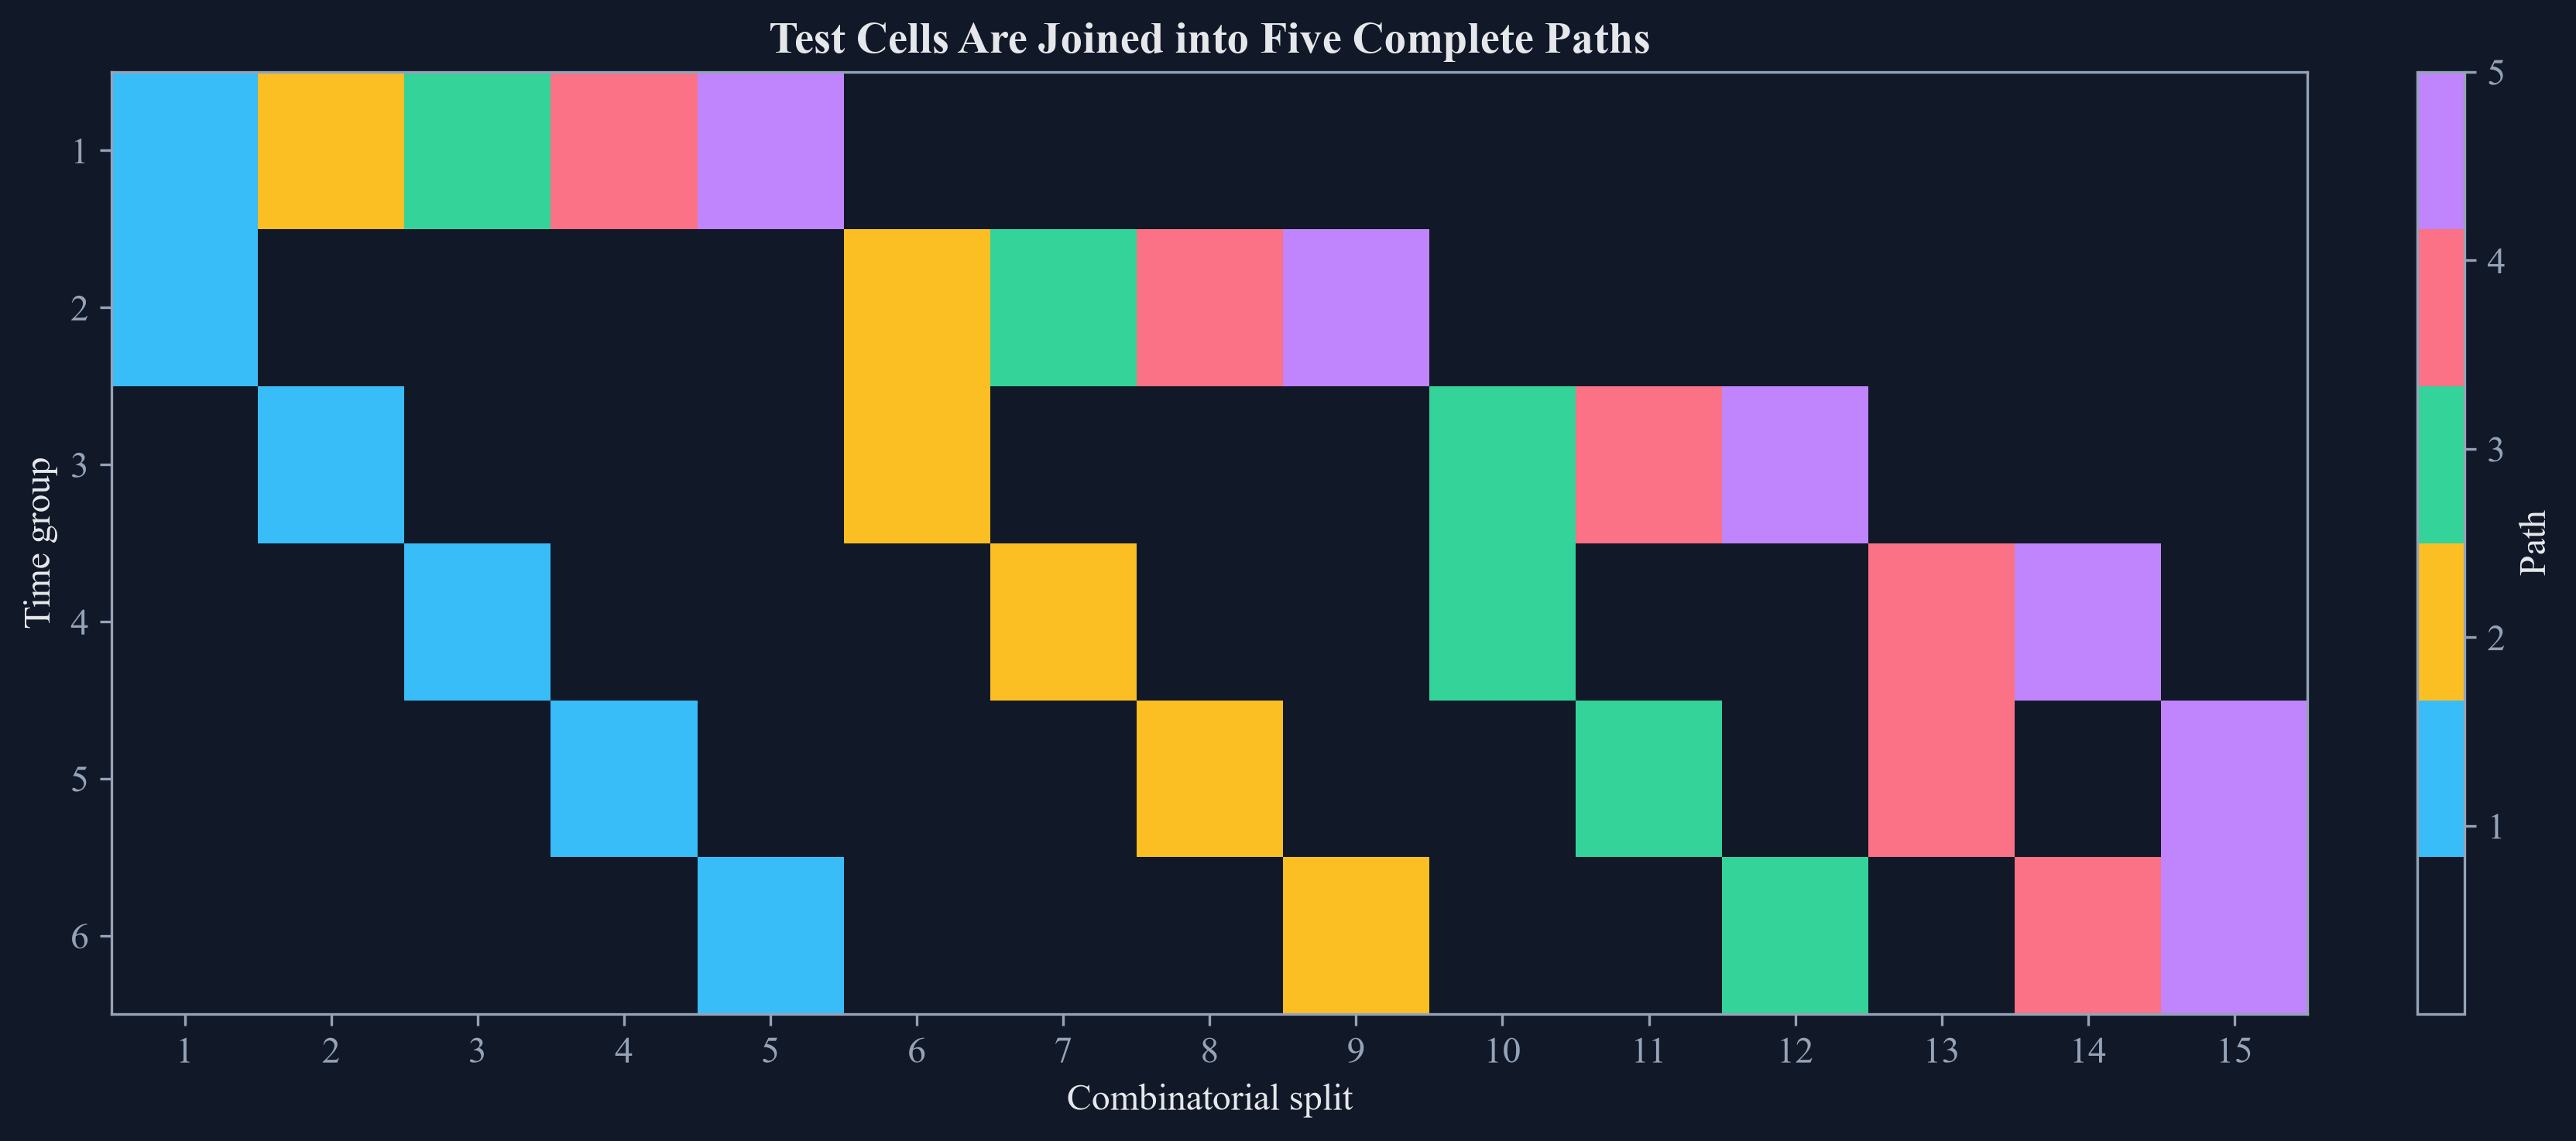

In [4]:
assignment = np.zeros_like(incidence)
assignment_records = []
for path, coordinates in sorted(locations.items()):
    for group_index, split_index in coordinates:
        assignment[group_index, split_index] = path
        assignment_records.append({
            "Path": path,
            "Time group": group_index + 1,
            "Split": split_index + 1,
            "Full test combination": " and ".join(str(value + 1) for value in combinations_list[split_index]),
        })
path_assignment = pd.DataFrame(assignment_records).sort_values(["Path", "Time group"]).reset_index(drop=True)
save_table(path_assignment, "path_assignment", "Assignment of tested time groups to five complete paths.", "tab:chapter15-path-assignment", fit=False)
display(path_assignment)

assignment_colors = ListedColormap([palette["axes"], palette["cyan"], palette["amber"], palette["green"], palette["rose"], palette["violet"]])
figure, axis = plt.subplots(figsize=(11.0, 4.8), constrained_layout=True)
image = axis.imshow(assignment, aspect="auto", interpolation="nearest", cmap=assignment_colors, vmin=0, vmax=len(locations))
axis.set_title("Test Cells Are Joined into Five Complete Paths")
axis.set_xlabel("Combinatorial split")
axis.set_ylabel("Time group")
axis.set_xticks(np.arange(len(combinations_list)))
axis.set_xticklabels(np.arange(1, len(combinations_list) + 1))
axis.set_yticks(np.arange(n_groups))
axis.set_yticklabels(np.arange(1, n_groups + 1))
colorbar = figure.colorbar(image, ax=axis, ticks=np.arange(1, len(locations) + 1))
colorbar.set_label("Path")
figure.savefig(FIGURES / "path_assignment.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "path_assignment.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "path_assignment.png")))
plt.close(figure)

The nominal share available for fitting in each split is:

$$
\theta(N,k)=1-\frac{k}{N}.
$$

Here, $\theta(N,k)$ is the training share before purging and embargo, $N$ is the total number of groups, and $k$ is the number of tested groups. Increasing $k$ creates more paths but leaves less data for fitting.

## Relating training share to the number of paths

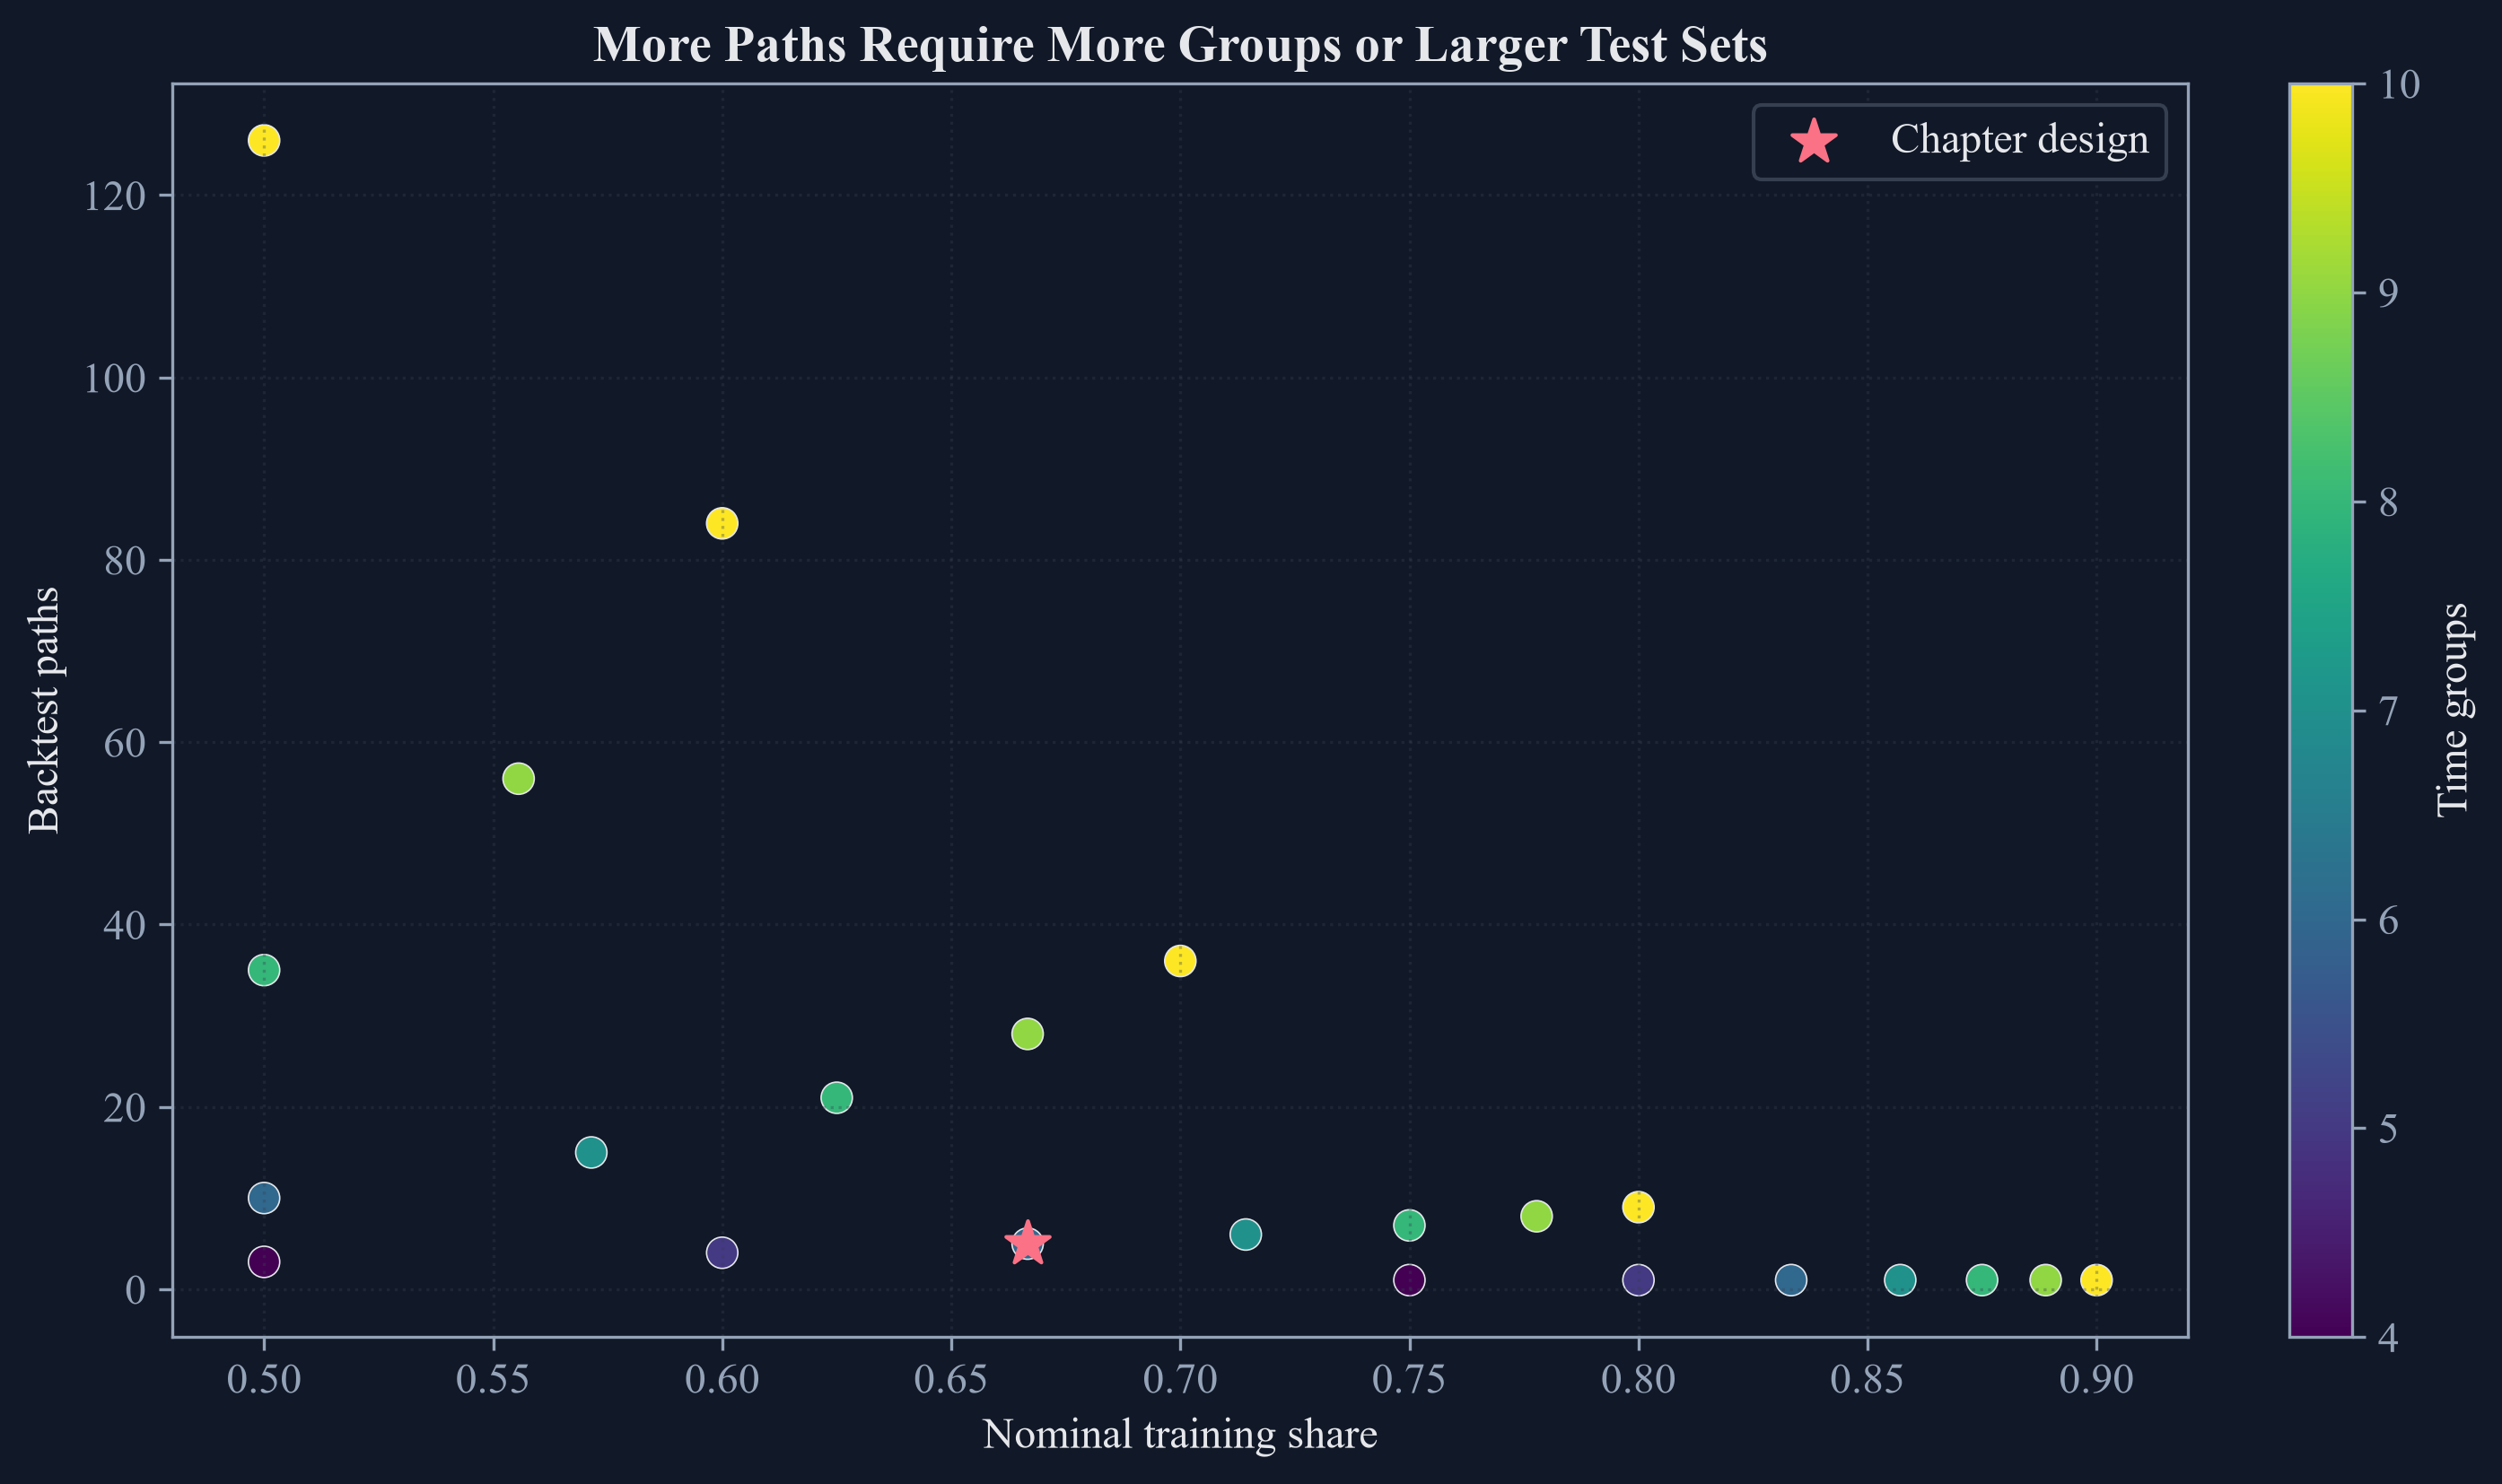

In [5]:
figure, axis = plt.subplots(figsize=(9.2, 5.4), constrained_layout=True)
points = axis.scatter(combinatorial_counts["Nominal training share"], combinatorial_counts["Backtest paths"], c=combinatorial_counts["Groups"], cmap="viridis", s=70, edgecolors=palette["text"], linewidths=0.4)
selected = combinatorial_counts[(combinatorial_counts["Groups"] == n_groups) & (combinatorial_counts["Test groups"] == n_test_groups)].iloc[0]
axis.scatter([selected["Nominal training share"]], [selected["Backtest paths"]], color=palette["rose"], s=150, marker="*", label="Chapter design")
axis.set_title("More Paths Require More Groups or Larger Test Sets")
axis.set_xlabel("Nominal training share")
axis.set_ylabel("Backtest paths")
axis.grid(alpha=0.35)
axis.legend()
figure.colorbar(points, ax=axis, label="Time groups")
figure.savefig(FIGURES / "split_training_tradeoff.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "split_training_tradeoff.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "split_training_tradeoff.png")))
plt.close(figure)

## Tests

In [6]:
assert len(public_x) == 2951
assert len(combinations_list) == 15
assert incidence.shape == (6, 15)
assert np.all(incidence.sum(axis=0) == 2)
assert np.all(incidence.sum(axis=1) == 5)
assert len(locations) == 5
assert all((len(coordinates) == 6 for coordinates in locations.values()))
assert np.count_nonzero(assignment) == 30
assert np.array_equal(assignment > 0, incidence > 0)
assert path_assignment.shape == (30, 4)
assert group_test_coverage['Test appearances'].eq(5).all()
assert group_test_coverage['Path segments'].eq(5).all()
assert combinatorial_counts.shape == (23, 7)
assert selected['Distinct splits'] == 15
assert selected['Backtest paths'] == 5
assert np.isclose(selected['Nominal training share'], 2 / 3)
assert (FIGURES / 'combinatorial_incidence.pdf').is_file()
assert (FIGURES / 'path_assignment.pdf').is_file()
assert (FIGURES / 'split_training_tradeoff.pdf').is_file()
assert (TABLES / 'data_provenance.tex').is_file()
assert (TABLES / 'combinatorial_counts.tex').is_file()
assert (TABLES / 'group_test_coverage.tex').is_file()
assert (TABLES / 'path_assignment.tex').is_file()
